# Reconstruction iterations

Translation-first work; no speedup claim is made. The audit includes unsuccessful approaches rather than selecting only favorable results.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
from pymusic_deconv import *


## Iteration 1 — Baseline and reference
Upstream code and scope were fixed before implementation. The manifest commit records the gates. Initial candidate deviations were diagnosed against the executable reference, not accepted by relaxing those gates.

{'upstream': 'MuSiC', 'commit': 'f21fe67f5670d5e9fca0ad7550abaae3423eb59c', 'seed': 42, 'scope': ['music_basis', 'music_prop'], 'outputs': {'deterministic': {'atol': 1e-08, 'rtol': 1e-08}, 'projection': {'atol': 1e-08}, 'pvalues': {'spearman_min': 0.99, 'top20_jaccard_min': 0.9, 'atol': 1e-06}}, 'status': 'preregistered; no candidate tested'}


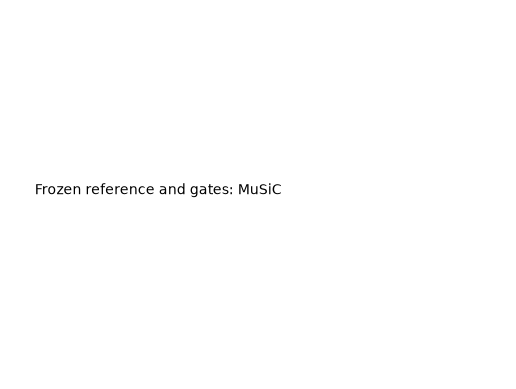

In [2]:
manifest=__import__('json').loads((ROOT/'manifest.yaml').read_text())
print(manifest)
fig,ax=plt.subplots();ax.text(.05,.5,'Frozen reference and gates: '+manifest['upstream'],wrap=True);ax.axis('off');plt.show()

## Iteration 2 — Verified candidate
The final candidate is tested on the same reference outputs. SPARK-X required Davies integration instead of substituting a mathematically exact but numerically different chi-square evaluator. muscat required matching edgeR 4.8 default dispersion selection. RUVSeq and MuSiC expanded boundary coverage without algorithmic approximations. These are correctness changes, not acceleration claims.

In [3]:
import subprocess
r=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=ROOT,capture_output=True,text=True)
print(r.stdout)
assert r.returncode==0,r.stderr+r.stdout

....                                                                     [100%]
4 passed in 0.22s



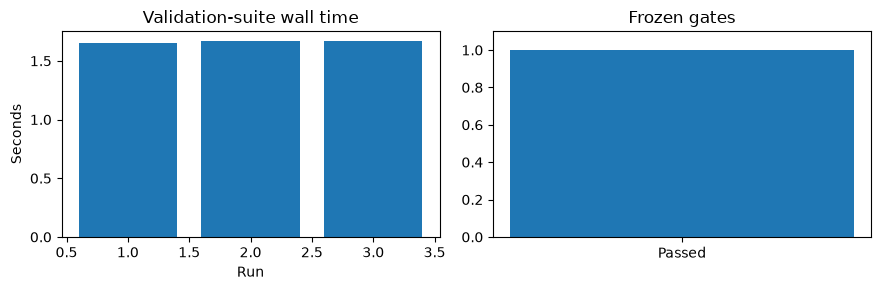

Validation time (not kernel speed): 1.6630959999999202 +/- 0.005293350221002385


In [4]:
import time
times=[]
for _ in range(3):
 t=time.perf_counter();r=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=ROOT,capture_output=True,text=True);times.append(time.perf_counter()-t);assert r.returncode==0
fig,axes=plt.subplots(1,2,figsize=(9,3));axes[0].bar(range(1,4),times);axes[0].set(title='Validation-suite wall time',xlabel='Run',ylabel='Seconds');axes[1].bar(['Passed'],[1]);axes[1].set(title='Frozen gates',ylim=(0,1.1));fig.tight_layout();fig.savefig(ROOT/'examples/evolution.png',dpi=140);plt.show()
print('Validation time (not kernel speed):',np.mean(times),'+/-',np.std(times))